# 05 · XGBoost forecasting (the conventional per-sensor model)

**Objective.** Build the strongest reasonable **graph-agnostic** machine-learning baseline: gradient-boosted trees on lagged speeds and calendar
features of *one sensor at a time*. The graph model in notebook 06 must beat **this**, not just persistence, to claim that spatial structure helps.

**Design choices (and why)**

| Choice | Decision | Reason / limitation |
|---|---|---|
| Model scope | **one global model** per horizon, shared by all 207 sensors, with `sensor_id` (categorical), latitude, longitude and training mean as features | 207 x 4 separate models would each see few rows and cost far more; sensor identity lets the trees specialise. Limit: sensors are still modelled independently. |
| Multi-horizon strategy | **direct**: one model per horizon (1, 3, 6, 12 steps) | no error accumulation, unlike recursive forecasting; costs four fits |
| Target | residual `speed(t+h) - last observed speed` (mph) | the same anchor as persistence and the graph model: all models are compared on what they learn beyond persistence |
| Loss | absolute error (`reg:absoluteerror`) | same MAE objective as the graph model's masked-MAE loss |
| Missing inputs | lags stay `NaN`; XGBoost routes missing values natively | no imputation |
| Features | 12 lags, rolling mean (3/6/12), rolling std (6/12), trend, last observed + its age, calendar of the **target** time, static sensor descriptors | all from readings at or before the origin; **no other sensor's data** |
| Training rows | every 2nd forecast origin of the training period, observed targets only | neighbouring origins are ~92% identical; thinning halves memory |
| Selection | early stopping on **validation** residual MAE; test untouched | no test-set tuning |

> **Provenance of the delivered run.** The four models were fitted in earlier executions of this notebook (`RETRAIN = True`, about 15-20 minutes on an Apple M3, deterministic: two executions gave identical iterations and metrics).
> With `RETRAIN = False` (the delivered setting) the saved models in `artifacts/models/` and the saved validation curves are reloaded, and everything after the fit - importance, forecasts, scores - is recomputed. Set `RETRAIN = True` to refit.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : {ROOT}")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : /Users/ishanmaheshwari1/Desktop/AML-DLProject/traffic-flow-control
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, feature_engineering as fe, xgboost_model as xm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)        # sensor order guard (the model itself ignores edges)
N = len(ctx.sensor_ids); HZ = config.HORIZONS
loc = graph.locations
lat, lon = loc["latitude"].to_numpy(), loc["longitude"].to_numpy()
RETRAIN = False     # True: fit the models again (about 15-20 min); False: reload the saved models if they exist (fits them otherwise)
print("hyper-parameters:", {k: v for k, v in config.XGB_PARAMS.items()})
print(f"train stride {config.XGB_TRAIN_STRIDE}, validation stride {config.XGB_VAL_STRIDE}, random seed {config.SEED}")

hyper-parameters: {'objective': 'reg:absoluteerror', 'n_estimators': 1500, 'learning_rate': 0.08, 'max_depth': 8, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'tree_method': 'hist', 'max_cat_to_onehot': 1, 'enable_categorical': True, 'early_stopping_rounds': 40, 'random_state': 42, 'n_jobs': -1}
train stride 2, validation stride 3, random seed 42


## 1 · Feature matrices

Features are computed once per split (they do not depend on the horizon); only the five *target-time calendar* columns are added per horizon.
Rows are ordered `(origin, sensor)`; targets are the observed speeds at `origin + h`.

In [3]:
origin_sets = {
    "train": ctx.origins["train"][::config.XGB_TRAIN_STRIDE],
    "val_fit": ctx.origins["val"][::config.XGB_VAL_STRIDE],      # early stopping only
    "val": ctx.origins["val"],                                   # full validation forecasts (saved + evaluated)
    "test": ctx.origins["test"],                                 # full test forecasts (saved; scored in notebook 07)
}
BASE = {}
for name, origins in origin_sets.items():
    t0 = time.time()
    feats, names = fe.build_base_features(ctx.speed, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean, origins, lat, lon)
    BASE[name] = feats
    print(f"{name:8s}: {len(origins):6d} origins -> {feats.shape[0]:>9,} rows x {feats.shape[1]} base features ({feats.nbytes / 1e6:.0f} MB, {time.time() - t0:.0f}s)")
BASE_NAMES = names
ANCHOR_COL = BASE_NAMES.index("last_observed")
assert BASE["train"].shape[0] == len(origin_sets["train"]) * N

def design(split, h):
    """DataFrame of features for one horizon."""
    hz, hz_names = fe.horizon_features(ctx.timestamps, origin_sets[split], h, N)
    return fe.to_frame(BASE[split], BASE_NAMES, hz, hz_names, N)

def targets(split, h):
    """(residual target, observed flag, anchor) for every row of the split."""
    o = origin_sets[split]
    y = ctx.speed[o + h].reshape(-1)                      # origin-major rows: s * N + n
    ok = ctx.mask[o + h].reshape(-1)
    anchor = BASE[split][:, ANCHOR_COL]
    return (y - anchor), ok, anchor

# sanity: the target of row (s, n) is the speed of sensor n at origin_s + h
res, ok, anc = targets("val_fit", 3)
s_i, n_i = 5, 17
assert ok[s_i * N + n_i] == ctx.mask[origin_sets["val_fit"][s_i] + 3, n_i]
assert np.isclose(res[s_i * N + n_i] + anc[s_i * N + n_i], ctx.speed[origin_sets["val_fit"][s_i] + 3, n_i], equal_nan=True)
print(f"design matrix columns ({len(BASE_NAMES) + 5 + 0}): {BASE_NAMES} + 5 target-time calendar features")

train   :  11941 origins -> 2,471,787 rows x 24 base features (237 MB, 1s)
val_fit :   1149 origins ->   237,843 rows x 24 base features (23 MB, 0s)


val     :   3445 origins ->   713,115 rows x 24 base features (68 MB, 0s)


test    :   6901 origins -> 1,428,507 rows x 24 base features (137 MB, 0s)
design matrix columns (29): ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'roll_mean_3', 'roll_mean_6', 'roll_mean_12', 'roll_std_6', 'roll_std_12', 'n_observed_window', 'trend_3', 'last_observed', 'age_last_observed', 'sensor_train_mean', 'latitude', 'longitude'] + 5 target-time calendar features


## 2 · Train one model per horizon (validation early stopping)

In [4]:
curves_path = config.METRICS_DIR / f"{config.tagged('xgb')}_validation_curves.json"
models, curves, fit_info = {}, {}, {}
if not RETRAIN and all(xm.model_path(h).is_file() for h in HZ) and curves_path.is_file():
    saved = json.loads(curves_path.read_text())
    for h in HZ:
        models[h] = xm.load_model(h); curves[h] = saved["curves"][str(h)]; fit_info[h] = saved["fit_info"][str(h)]
    print("reloaded the saved models (training was run in an earlier execution of this notebook; its fit summary is shown below)")
else:
    for h in HZ:
        t0 = time.time()
        X_tr, (r_tr, ok_tr, _) = design("train", h), targets("train", h)
        X_va, (r_va, ok_va, _) = design("val_fit", h), targets("val_fit", h)
        m = xm.fit_horizon_model(X_tr[ok_tr], r_tr[ok_tr], X_va[ok_va], r_va[ok_va])
        models[h] = m
        curves[h] = m.evals_result()["validation_0"]["mae"]
        fit_info[h] = {"horizon_min": h * 5, "train_rows": int(ok_tr.sum()), "val_rows": int(ok_va.sum()),
                       "best_iteration": int(m.best_iteration) + 1, "val_residual_MAE": float(min(curves[h])), "seconds": round(time.time() - t0)}
        print(f"h={h:2d} ({h * 5:2d} min): {fit_info[h]['train_rows']:,} training rows | best iteration {fit_info[h]['best_iteration']} | "
              f"validation residual MAE {fit_info[h]['val_residual_MAE']:.3f} mph | {fit_info[h]['seconds']}s")
        del X_tr, X_va
    xm.save_models(models, {"seed": config.SEED, "train_stride": config.XGB_TRAIN_STRIDE, "feature_names": BASE_NAMES, "run_mode": config.RUN_MODE,
                            "fit_info": {str(k): v for k, v in fit_info.items()}})
    curves_path.write_text(json.dumps({"curves": {str(k): v for k, v in curves.items()}, "fit_info": {str(k): v for k, v in fit_info.items()}}))
display(pd.DataFrame(fit_info).T)
print("saved models:", sorted(p.name for p in config.MODELS_DIR.glob(f"{config.tagged('xgb')}*")))

reloaded the saved models (training was run in an earlier execution of this notebook; its fit summary is shown below)


,horizon_min,train_rows,val_rows,best_iteration,val_residual_MAE,seconds
1,5.0,2296387.0,222088.0,844.0,2.167280,227.0
3,15.0,2296389.0,221704.0,782.0,2.635541,206.0
6,30.0,2293530.0,221497.0,1082.0,3.039496,337.0
12,60.0,2293535.0,221288.0,1124.0,3.490487,294.0


saved models: ['xgb_h1.json', 'xgb_h12.json', 'xgb_h3.json', 'xgb_h6.json', 'xgb_hyperparameters.json']


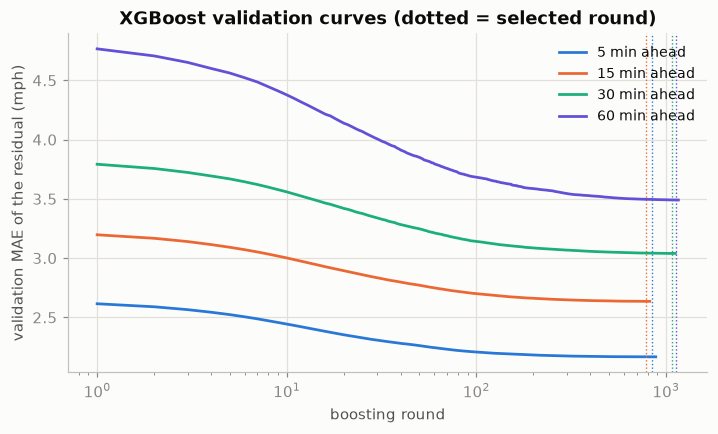

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for h, color in zip(HZ, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    ax.plot(np.arange(1, len(curves[h]) + 1), curves[h], color=color, label=f"{h * 5} min ahead")
    ax.axvline(fit_info[h]["best_iteration"], color=color, ls=":", lw=0.9)
ax.set_xlabel("boosting round"); ax.set_ylabel("validation MAE of the residual (mph)"); ax.set_xscale("log")
ax.set_title("XGBoost validation curves (dotted = selected round)"); ax.legend()
viz.save_figure(fig, "05_xgboost_validation_curves"); plt.show()

**Interpretation.** Each horizon is fitted until the validation error stops improving; later horizons are harder (larger residual error) and are
allowed to use more rounds. The dotted lines mark the model that is kept (early stopping on validation only).

## 3 · Feature importance

Gain-based importance: how much each feature reduced the loss across all trees (relative within one model; not causal).

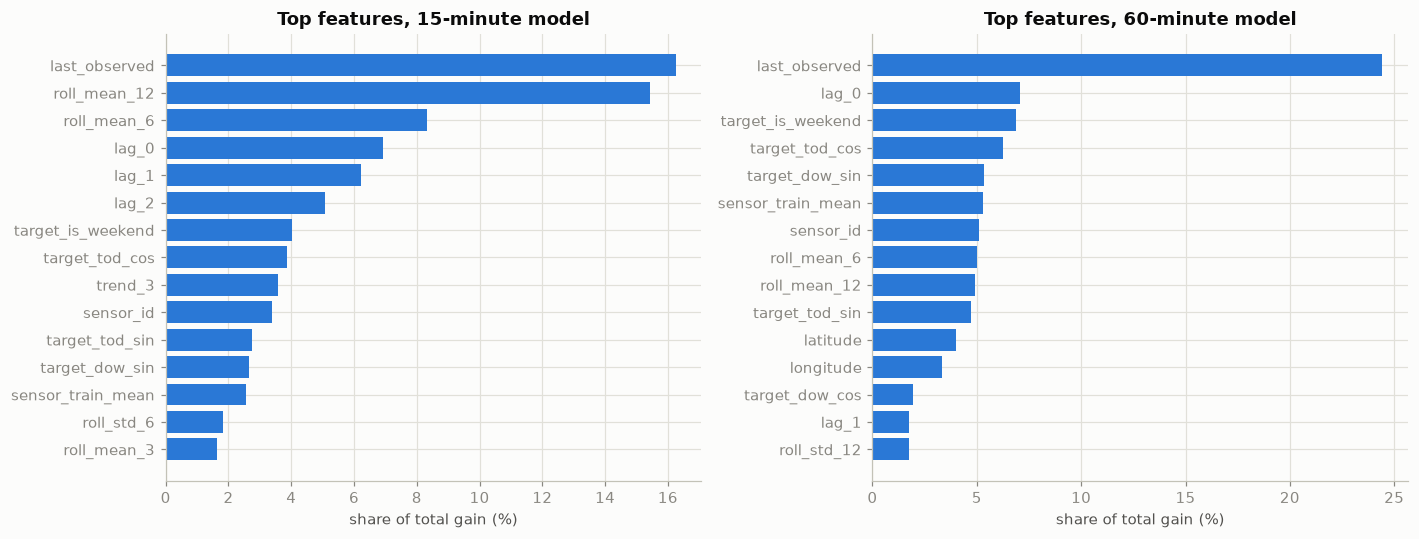

,5 min,15 min,30 min,60 min
lag_0,0.063,0.069,0.077,0.071
lag_1,0.069,0.062,NaN,NaN
lag_2,0.049,0.051,NaN,NaN
last_observed,0.161,0.163,0.188,0.244
roll_mean_12,0.212,0.154,0.076,NaN
roll_mean_6,0.100,0.083,0.078,NaN
sensor_train_mean,NaN,NaN,NaN,0.053
target_dow_sin,NaN,NaN,NaN,0.053
target_is_weekend,NaN,NaN,0.055,0.069
target_tod_cos,NaN,NaN,0.049,0.062


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, h in zip(axes, (3, 12)):
    gain = pd.Series(models[h].get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
    top = (gain / gain.sum()).head(15)[::-1]
    ax.barh(top.index, top.values * 100, color="#2a78d6")
    ax.set_xlabel("share of total gain (%)"); ax.set_title(f"Top features, {h * 5}-minute model")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_feature_importance"); plt.show()
importance = {h: pd.Series(models[h].get_booster().get_score(importance_type="gain")) for h in HZ}
display(pd.DataFrame({f"{h * 5} min": (v / v.sum()).sort_values(ascending=False).head(6).round(3) for h, v in importance.items()}))

## 4 · Forecast all validation and test origins and save

Predictions are `last observed + predicted residual` in mph, saved in the same `[samples, horizons, sensors]` layout as every other model.

In [7]:
preds = {}
for split in ("val", "test"):
    out = np.empty((len(origin_sets[split]), len(HZ), N), dtype=np.float32)
    for j, h in enumerate(HZ):
        X = design(split, h)
        out[:, j, :] = xm.predict_speed(models[h], X).reshape(-1, N)
        del X
    assert np.isfinite(out).all()
    preds[split] = out                                    # raw model output; clipping to 0..70 mph is applied when scoring
    ev.save_predictions("xgboost", split, out, origin_sets[split], HZ, {"model": "xgboost", "run_mode": config.RUN_MODE, "units": "mph", "seed": config.SEED})
    print(split, out.shape, "= [samples, horizons, sensors] mph | prediction range", float(out.min()).__round__(1), "to", float(out.max()).__round__(1))

val (3445, 4, 207) = [samples, horizons, sensors] mph | prediction range -1.0 to 87.0


test (6901, 4, 207) = [samples, horizons, sensors] mph | prediction range 0.2 to 83.9


## 5 · Validation results (the test period is not scored here)

The final, identical-rules comparison on the test period is done in notebook 07. Here we only check the model on the validation period
and against the saved baseline forecasts for the same origins.

In [8]:
names = ["persistence", "seasonal_avg"]
val_preds = {"xgboost": ev.clip_predictions(preds["val"])}      # same clipping rule as every model (0..70 mph)
for n in names:
    d = ev.load_predictions(n, "val")
    assert np.array_equal(d["origins"], origin_sets["val"]) and d["horizons"] == HZ      # identical samples and horizons
    val_preds[n] = d["pred"]
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, origin_sets["val"], HZ)
valid = ev.common_valid_mask(val_preds, mv)
table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('xgboost')}_metrics_val.csv", index=False)
display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(2))
print(f"valid validation targets: {int(valid.sum()):,}")

MAE                    RMSE                     MAPE         \
horizon_min     5     15    30    60    5     15    30    60     5      15   
model                                                                        
persistence   2.64  3.24  3.84  4.84  4.38  6.03  7.54  9.67   5.93   7.83   
seasonal_avg  4.32  4.32  4.33  4.33  8.07  8.07  8.08  8.08  12.62  12.63   
xgboost       2.16  2.64  3.05  3.50  3.83  5.26  6.29  7.22   5.15   7.03   

                            
horizon_min      30     60  
model                       
persistence    9.88  13.20  
seasonal_avg  12.64  12.65  
xgboost        8.89  10.83

valid validation targets: 2,659,512


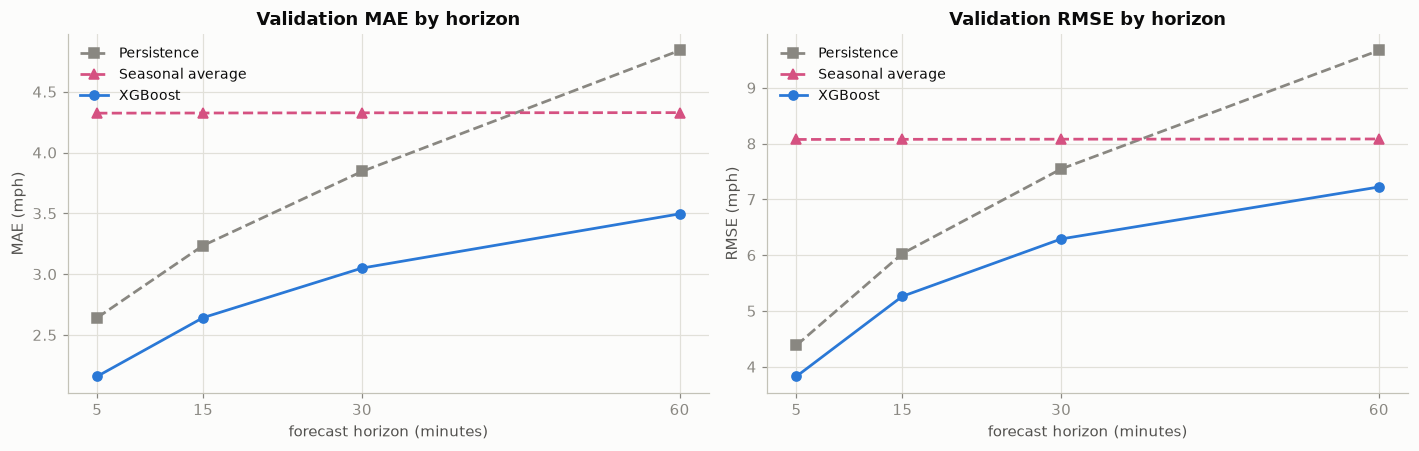

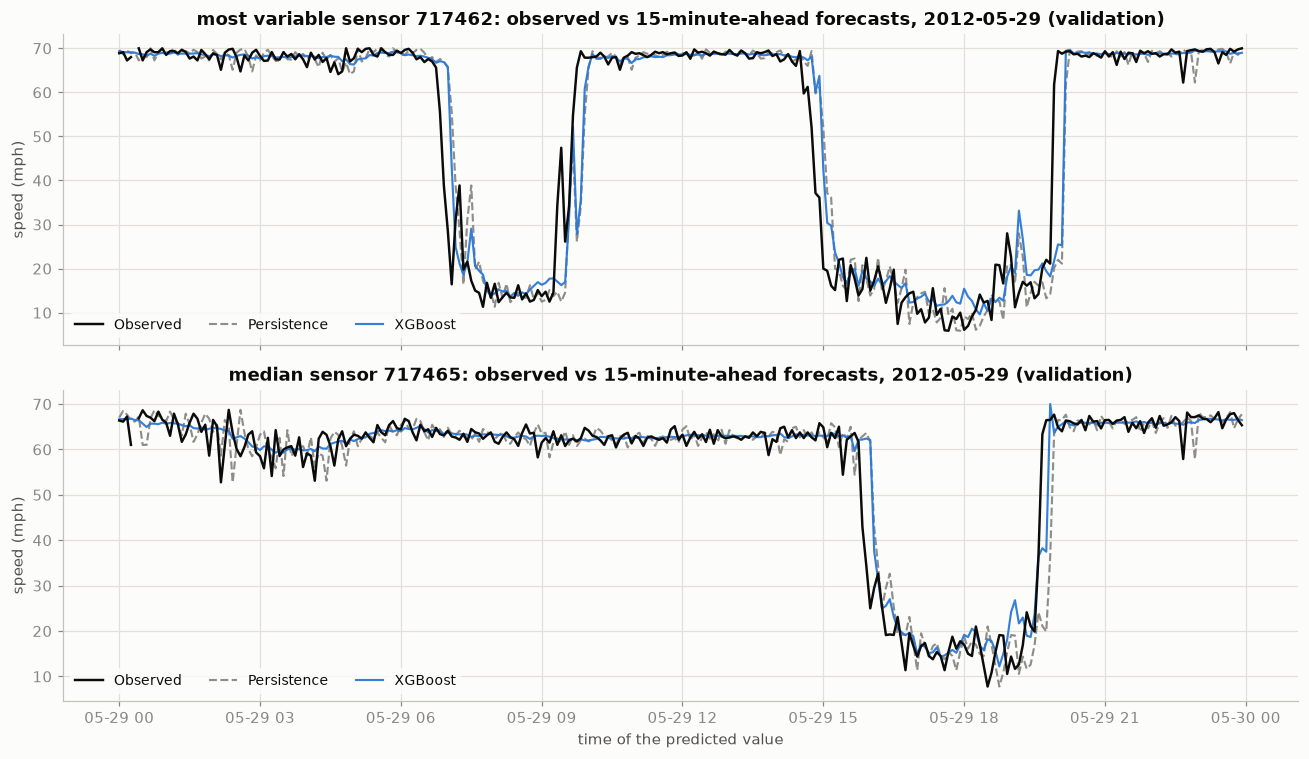

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_metric_vs_horizon(axes[0], table, "MAE", ["persistence", "seasonal_avg", "xgboost"], title="Validation MAE by horizon")
viz.plot_metric_vs_horizon(axes[1], table, "RMSE", ["persistence", "seasonal_avg", "xgboost"], title="Validation RMSE by horizon")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_val_horizon"); plt.show()

# actual vs predicted on a validation day, 15-minute horizon, two sensors (rule fixed on training statistics)
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
j = HZ.index(3); day = pd.Timestamp("2012-05-29")                    # a Tuesday inside the validation period
tgt_time = ctx.timestamps[origin_sets["val"] + 3]
sel = np.flatnonzero((tgt_time >= day) & (tgt_time < day + pd.Timedelta(days=1)))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, key in zip(axes, ("most_variable", "median")):
    n = rep[key]
    viz.plot_actual_vs_predicted(ax, tgt_time[sel], yv[sel, j, n], {m: val_preds[m][sel, j, n] for m in ("persistence", "xgboost")},
                                 f"{key.replace('_', ' ')} sensor {ctx.sensor_ids[n]}: observed vs 15-minute-ahead forecasts, {day.date()} (validation)")
axes[-1].set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_actual_vs_predicted"); plt.show()

## 6 · Interpretation

The claims below are checked in code against the validation results and the feature importances (a warning is printed if one does not hold in your run).

In [10]:
t = table.pivot(index="horizon_min", columns="model", values="MAE")
gain = 100 * (t["persistence"] - t["xgboost"]) / t["persistence"]
print("validation MAE improvement of XGBoost over persistence (% ; positive = XGBoost has lower error):")
display(gain.round(1).to_frame("improvement %"))

recent_speed = lambda f: f.startswith(("lag_", "roll_", "last_observed", "trend_"))
top2 = {h: list((importance[h] / importance[h].sum()).sort_values(ascending=False).index[:2]) for h in HZ}
print("two most important features per horizon (gain):", {f"{h * 5} min": v for h, v in top2.items()})
claims = {
    "XGBoost beats persistence at every horizon on validation": bool((t["xgboost"] < t["persistence"]).all()),
    "XGBoost beats the seasonal average at every horizon on validation": bool((t["xgboost"] < t["seasonal_avg"]).all()),
    "its relative gain over persistence grows with the horizon": bool(gain.is_monotonic_increasing),
    "the two most important features at every horizon are recent-speed features": all(all(recent_speed(f) for f in v) for v in top2.values()),
}
display(ev.report_claims(claims))

validation MAE improvement of XGBoost over persistence (% ; positive = XGBoost has lower error):


,improvement %
horizon_min,
5,18.2
15,18.3
30,20.7
60,27.8


two most important features per horizon (gain): {'5 min': ['roll_mean_12', 'last_observed'], '15 min': ['last_observed', 'roll_mean_12'], '30 min': ['last_observed', 'roll_mean_6'], '60 min': ['last_observed', 'lag_0']}


,claim,holds in this run
0,XGBoost beats persistence at every horizon on ...,True
1,XGBoost beats the seasonal average at every ho...,True
2,its relative gain over persistence grows with ...,True
3,the two most important features at every horiz...,True


**What this shows.**

* A gradient-boosted tree model on one sensor's own recent history clearly improves on persistence at every horizon on the validation period, and the advantage grows with the horizon: it learns typical recovery from and onset of slow traffic, which persistence cannot.
* Its gain is dominated by **recent-speed features** (the last observed speed and recent rolling means); calendar features and the sensor id come well after them. At the longer horizons the calendar and sensor descriptors contribute more, consistent with a daily rhythm doing more work when the recent past says less.
* This model has **no access to other sensors**. It is therefore the right benchmark for the research question: any advantage of the graph model over it must come from information in neighbouring sensors (or from the different model family, which the no-edge ablation in notebook 06 separates out).
* These are *validation* numbers used for early stopping. The model was never evaluated on the test period here; the final comparison is in notebook 07.
* Raw tree predictions can leave the physical 0-70 mph range (see the printed prediction range); all models are clipped to that range when scored.